# Training Model — audit delapan eksperimen

Notebook ini mendokumentasikan resep dan **artefak training yang sudah ada** untuk YOLO26m-seg, Swin-L + Mask2Former, EVA-02-L + Cascade Mask R-CNN, dan ECSeg-L; masing-masing pretrained dan scratch.

Sel di bawah membaca berkas log/CSV lokal untuk membuat ringkasan dan grafik. Sel tidak memulai training. Swin-L dan EVA sebelumnya dijalankan di Modal; YOLO26m dan ECSeg-L dijalankan lokal. Path dibuat relatif terhadap root proyek, jadi notebook bisa dibuka dari folder mana pun di dalam proyek.

> Angka validasi mengikuti `reports/MODEL_DIRECTORY.md`. Scratch Swin-L dan EVA berhenti manual, sedangkan ECSeg-L scratch selesai pada anggaran epoch-nya. Grafik hanya menggambarkan epoch yang tercatat, bukan klaim bahwa seluruh run selesai.

In [11]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Cari root repo dari notebook dan artefak training, bukan marker folder induk.
_cwd = Path.cwd().resolve()
_ancestors = [_cwd, *_cwd.parents]
_candidates = [*_ancestors, *(p / "ComVisInstanceSegmentation" for p in _ancestors)]
ROOT = next((p for p in _candidates if (p / "Training Model.ipynb").is_file() and (p / "reports" / "training_evidence" / "yolo26m").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Tidak menemukan root repo yang berisi Training Model.ipynb dan reports/training_evidence/yolo26m/.")

RUNS = {
    "YOLO26m pretrained": {"csv": "reports/training_evidence/yolo26m/k35_m_pf0/results.csv", "log": "reports/training_evidence/yolo26m/k35_m_pf0/train.log", "kind": "yolo"},
    "YOLO26m scratch": {"csv": "reports/training_evidence/yolo26m/k35_m_sf0_c3/results.csv", "log": "reports/training_evidence/yolo26m/k35_m_sf0_c3/train.log", "kind": "yolo"},
    "Swin-L pretrained": {"csv": "reports/training_evidence/swin_l_mask2former/pretrained/results.csv", "log": "reports/training_evidence/swin_l_mask2former/pretrained/train.log", "kind": "swin"},
    "Swin-L scratch": {"csv": "reports/training_evidence/swin_l_mask2former/scratch/results.csv", "log": "reports/training_evidence/swin_l_mask2former/scratch/train.log", "kind": "swin"},
    "EVA-02-L pretrained": {"csv": "reports/training_evidence/eva_cascade_mask_rcnn/pretrained/results.csv", "log": "reports/training_evidence/eva_cascade_mask_rcnn/pretrained/train.log", "kind": "eva"},
    "EVA-02-L scratch": {"csv": "reports/training_evidence/eva_cascade_mask_rcnn/scratch/results.csv", "log": "reports/training_evidence/eva_cascade_mask_rcnn/scratch/train.log", "kind": "eva"},
    "ECSeg-L pretrained": {"csv": None, "log": "reports/training_evidence/ecseg_l/pretrained/log.txt", "kind": "ecseg"},
    "ECSeg-L scratch": {"csv": None, "log": "reports/training_evidence/ecseg_l/scratch/log.txt", "kind": "ecseg"},
}

print(f"Root proyek: {ROOT}")
print(f"Jumlah run yang akan diringkas: {len(RUNS)}")

Root proyek: C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\ComVisInstanceSegmentation
Jumlah run yang akan diringkas: 8


## Resep training dan cara menjalankan ulang

Perintah di bawah hanya disimpan sebagai referensi. Jangan jalankan ulang tanpa mengganti nama output dan memastikan GPU/Modal serta biaya tersedia. Checkpoint/log yang tercatat berasal dari eksperimen sebelumnya; konfigurasi finalnya ada di file run masing-masing.

YOLO26m memakai `scripts/train_k35.py`; ECSeg-L memakai config EdgeCrafter yang tersimpan. Swin-L dan EVA memakai entry point Modal di `modal/`. Baris perintah Modal hanya dokumentasi; notebook ini tidak mengirim job.

In [7]:
# Referensi resep training (string saja; tidak dieksekusi oleh notebook).
TRAINING_RECIPES = {
    "YOLO26m pretrained": "python scripts/train_k35.py --model m --arm pretrained --fold 0 --epochs 24 --batch 4 --tag k35_m_pf0",
    "YOLO26m scratch": "python scripts/train_k35.py --model m --arm scratch --fold 0 --epochs 48 --batch 4 --resume-from reports/training_evidence/yolo26m/k35_m_sf0_c2/weights/last.pt --tag k35_m_sf0_c3",
    "Swin-L pretrained (Modal)": "modal run modal/m2f_train_v2.py --mode train --arm pretrained --epochs 150 --batch 2 --seed 0",
    "Swin-L scratch (Modal)": "modal run modal/m2f_train_v2.py --mode train --arm scratch --epochs 150 --batch 2 --seed 0",
    "EVA-02-L pretrained (Modal)": "modal run modal/eva_train.py --fold 0 --epochs 40 --batch 2 --pretrained",
    "EVA-02-L scratch (Modal)": "modal run modal/eva_train.py --fold 0 --epochs 120 --batch 2 --no-pretrained",
    "ECSeg-L pretrained": "cd third_party/EdgeCrafter/ecdetseg && python train.py -c configs/ecseg/ecseg_l_k35_ws.yml -t ecvits/ecseg_l.pth --seed 0",
    "ECSeg-L scratch": "cd third_party/EdgeCrafter/ecdetseg && python train.py -c configs/ecseg/ecseg_l_k35_scratch.yml --seed 0",
}

# Waspadai: perintah di atas adalah template dokumentasi, bukan jaminan
# bahwa semua argumen cocok untuk mereproduksi kondisi run lama secara bit-per-bit.
# Gunakan args.yaml/config, metrics.json, dan log run sebagai sumber kebenaran.
for name, command in TRAINING_RECIPES.items():
    print(f"{name}:\n  {command}\n")

YOLO26m pretrained:
  python scripts/train_k35.py --model m --arm pretrained --fold 0 --epochs 24 --batch 4 --tag k35_m_pf0

YOLO26m scratch:
  python scripts/train_k35.py --model m --arm scratch --fold 0 --epochs 48 --batch 4 --resume-from reports/training_evidence/yolo26m/k35_m_sf0_c2/weights/last.pt --tag k35_m_sf0_c3

Swin-L pretrained (Modal):
  modal run modal/m2f_train_v2.py --mode train --arm pretrained --epochs 150 --batch 2 --seed 0

Swin-L scratch (Modal):
  modal run modal/m2f_train_v2.py --mode train --arm scratch --epochs 150 --batch 2 --seed 0

EVA-02-L pretrained (Modal):
  modal run modal/eva_train.py --fold 0 --epochs 40 --batch 2 --pretrained

EVA-02-L scratch (Modal):
  modal run modal/eva_train.py --fold 0 --epochs 120 --batch 2 --no-pretrained

ECSeg-L pretrained:
  cd third_party/EdgeCrafter/ecdetseg && python train.py -c configs/ecseg/ecseg_l_k35_ws.yml -t ecvits/ecseg_l.pth --seed 0

ECSeg-L scratch:
  cd third_party/EdgeCrafter/ecdetseg && python train.py -c c

## Fungsi baca log, ringkasan, dan kurva

Grafik menampilkan metrik yang benar-benar dicatat setiap training: YOLO menggunakan kolom mask mAP50-95 Ultralytics; Swin-L dan EVA menggunakan AP mask COCO; ECSeg-L mengambil AP/AP50 dari array `test_coco_eval_mask` pada log JSON. Skala metrik tidak sepenuhnya seragam untuk YOLO, sesuai catatan protokol di `MODEL_DIRECTORY.md`.

In [12]:
def _load_run(name, spec):
    """Muat riwayat CSV atau log JSON ECSeg; tidak memulai training."""
    if spec["kind"] == "ecseg":
        log_path = ROOT / spec["log"]
        if not log_path.exists():
            raise FileNotFoundError(log_path)
        rows = []
        for line in log_path.read_text(encoding="utf-8").splitlines():
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            ap = obj.get("test_coco_eval_mask")
            rows.append({"epoch": int(obj.get("epoch", len(rows))),
                         "train_loss": obj.get("train_loss"),
                         "val_AP": ap[0] if isinstance(ap, list) and len(ap) else None,
                         "val_AP50": ap[1] if isinstance(ap, list) and len(ap) > 1 else None})
        return pd.DataFrame(rows), log_path
    csv_path = ROOT / spec["csv"]
    log_path = ROOT / spec["log"]
    if not csv_path.exists():
        raise FileNotFoundError(csv_path)
    return pd.read_csv(csv_path), log_path


def _metric_columns(name, df, kind):
    cols = list(df.columns)
    if kind == "yolo":
        ap = next((c for c in cols if c.strip() == "metrics/mAP50-95(M)"), None)
        losses = [c for c in cols if c.strip().startswith("train/") and c.strip().endswith("_loss")]
        return ap, losses[:3]
    ap = next((c for c in ("val_AP", "val_best_ap") if c in cols), None)
    if kind == "ecseg":
        return "val_AP", ["train_loss"]
    loss = next((c for c in ("loss_mean", "loss", "train_loss") if c in cols), None)
    return ap, [loss] if loss else []


def show_run(name, spec):
    df, log_path = _load_run(name, spec)
    if df.empty:
        print(f"{name}: log/CSV tidak memiliki baris metrik.")
        return
    epoch_col = next((c for c in ("epoch", "Epoch") if c in df.columns), None)
    if epoch_col is None:
        df = df.copy()
        df["epoch"] = range(1, len(df) + 1)
        epoch_col = "epoch"
    ap_col, loss_cols = _metric_columns(name, df, spec["kind"])
    print(f"### {name} — {len(df)} baris tercatat")
    print(f"Log: {log_path.relative_to(ROOT)} ({'ada' if log_path.exists() else 'tidak ditemukan'})")
    view_cols = [c for c in [epoch_col, ap_col, *loss_cols] if c and c in df.columns]
    if view_cols:
        display(df[view_cols].tail(8).round(5))
    if log_path.exists():
        lines = log_path.read_text(encoding="utf-8", errors="replace").splitlines()
        # ECSeg menulis satu JSON panjang per epoch; ringkas log itu ke metrik inti.
        if spec["kind"] == "ecseg":
            print("Cuplikan log (metrik inti tiap epoch terakhir):")
            for line in lines[-3:]:
                try:
                    obj = json.loads(line)
                    ap = obj.get("test_coco_eval_mask", [])
                    print({"epoch": obj.get("epoch"), "train_loss": round(obj.get("train_loss", 0), 4),
                           "val_AP": round(ap[0], 6) if ap else None,
                           "val_AP50": round(ap[1], 6) if len(ap) > 1 else None})
                except (json.JSONDecodeError, TypeError):
                    print(line[:250])
        else:
            print("Cuplikan akhir log:")
            print("\n".join(lines[-5:]))
    else:
        print("Log teks tidak tersedia; kurva dibaca dari CSV.")

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    x = pd.to_numeric(df[epoch_col], errors="coerce")
    if ap_col and ap_col in df.columns:
        y = pd.to_numeric(df[ap_col], errors="coerce")
        valid = y.notna()
        axes[0].plot(x[valid], y[valid], marker="o", ms=3)
        axes[0].set_title(f"Validasi: {ap_col}")
        axes[0].set_ylabel("AP / mAP")
    else:
        axes[0].text(.5, .5, "Tidak ada AP validasi di CSV", ha="center", va="center")
        axes[0].set_title("AP validasi")
    axes[0].set_xlabel("Epoch")
    for col in loss_cols:
        if col in df.columns:
            y = pd.to_numeric(df[col], errors="coerce")
            valid = y.notna()
            if valid.any():
                axes[1].plot(x[valid], y[valid], label=col, linewidth=1.2)
    axes[1].set_title("Loss training")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    if axes[1].lines:
        axes[1].legend(fontsize=7)
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()

## YOLO26m — pretrained dan scratch

Training dilakukan lokal dengan Ultralytics pada fold 0, 35 kelas, resolusi 640. Run pretrained tercatat 24 epoch; scratch merupakan tahap terakhir warm restart (`c3`) sepanjang 48 epoch pada run ini. Grafik membaca `results.csv`; log ditampilkan dari `train.log`.

### YOLO26m pretrained — 24 baris tercatat
Log: reports\training_evidence\yolo26m\k35_m_pf0\train.log (ada)


,epoch,metrics/mAP50-95(M),train/box_loss,train/seg_loss,train/cls_loss
16,17,0.32046,0.90744,1.37044,3.29274
17,18,0.32346,0.91766,1.35519,3.22604
18,19,0.33039,0.88302,1.32790,3.17391
19,20,0.33722,0.88961,1.28978,2.95382
20,21,0.33337,0.86281,1.22584,2.93987
21,22,0.32569,1.00491,1.33904,3.29817
22,23,0.31824,0.95765,1.30394,3.11102
23,24,0.32250,0.88598,1.23723,2.92448


Cuplikan akhir log:
VAL mask mAP50-95=0.3347 mAP50=0.4783
kurva: ep1=0.1112 -> ep13=0.2895 -> ep24=0.3225
SELESAI complete | 20.5 menit | 51.1 s/epoch
RESULT {"tag": "k35_m_pf0", "cfg": {"tag": "k35_m_pf0", "model": "yolo26m-seg.pt", "arm": "pretrained", "fold": 0, "epochs": 24, "batch": 4, "imgsz": 640, "lr0": 0.0005, "lrf": 0.01, "warmup_epochs": 0.0, "close_mosaic": 3, "optimizer": "AdamW", "cls": 1.0, "copy_paste": 0.3, "workers": 0, "cache": "disk", "seed": 0, "deterministic": true, "nc": 35, "n_things": 24, "n_stuff": 11, "data": "C:\\Users\\Rafli\\Documents\\kodin\\python\\kompis\\Minggu 13\\local_ds\\k35_f0\\data.yaml", "device": "cuda:0"}, "status": "complete", "error": null, "train_seconds": 1227.3, "s_per_epoch": 51.1, "curve": {"1": 0.1112, "2": 0.0473, "3": 0.1073, "4": 0.1426, "5": 0.1664, "6": 0.1914, "7": 0.2042, "8": 0.2387, "9": 0.2598, "10": 0.2579, "11": 0.2738, "12": 0.2868, "13": 0.2895, "14": 0.3045, "15": 0.317, "16": 0.3317, "17": 0.3205, "18": 0.3235, "19": 0.

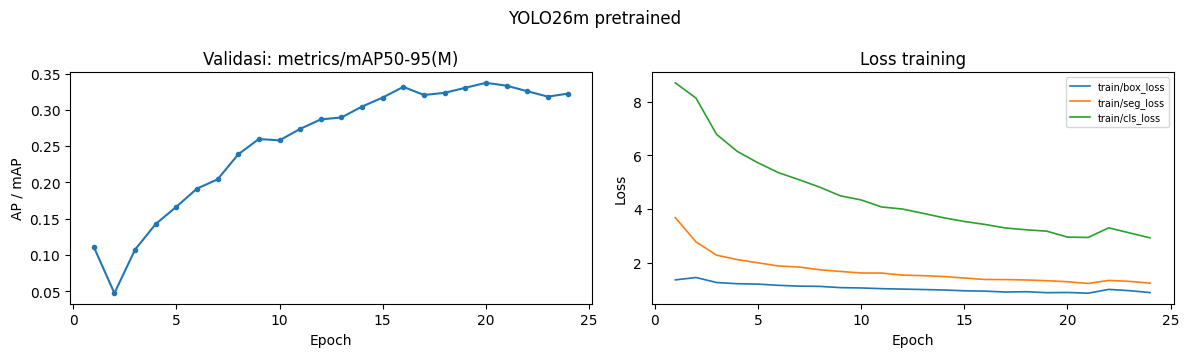

### YOLO26m scratch — 48 baris tercatat
Log: reports\training_evidence\yolo26m\k35_m_sf0_c3\train.log (ada)


,epoch,metrics/mAP50-95(M),train/box_loss,train/seg_loss,train/cls_loss
40,41,0.10293,1.66108,2.37693,4.91923
41,42,0.10176,1.66122,2.36188,4.87737
42,43,0.10132,1.64852,2.34676,4.80718
43,44,0.09979,1.67864,2.34359,4.89210
44,45,0.10174,1.66717,2.37942,4.84829
45,46,0.09074,1.88230,2.47220,5.28610
46,47,0.09502,1.81244,2.43917,5.05378
47,48,0.09656,1.79204,2.43716,4.93713


Cuplikan akhir log:
VAL mask mAP50-95=0.1016 mAP50=0.1860
kurva: ep1=0.0164 -> ep25=0.0827 -> ep48=0.0966
SELESAI complete | 44.9 menit | 56.1 s/epoch
RESULT {"tag": "k35_m_sf0_c3", "cfg": {"tag": "k35_m_sf0_c3", "model": "C:\\Users\\Rafli\\Documents\\kodin\\python\\kompis\\Minggu 13\\local_runs/k35_m_sf0_c2/weights/last.pt", "arm": "scratch", "fold": 0, "epochs": 48, "batch": 4, "imgsz": 640, "lr0": 0.001, "lrf": 0.01, "warmup_epochs": 0.0, "close_mosaic": 3, "optimizer": "AdamW", "cls": 1.0, "copy_paste": 0.3, "workers": 0, "cache": "disk", "seed": 0, "deterministic": true, "nc": 35, "n_things": 24, "n_stuff": 11, "data": "C:\\Users\\Rafli\\Documents\\kodin\\python\\kompis\\Minggu 13\\local_ds\\k35_f0\\data.yaml", "device": "cuda:0", "continued_from": {"from": "local_runs\\k35_m_sf0_c2\\weights\\last.pt", "saved_epoch": -1, "has_optimizer": false, "has_ema": false, "true_resume_possible": false}}, "status": "complete", "error": null, "train_seconds": 2691.4, "s_per_epoch": 56.1, "cur

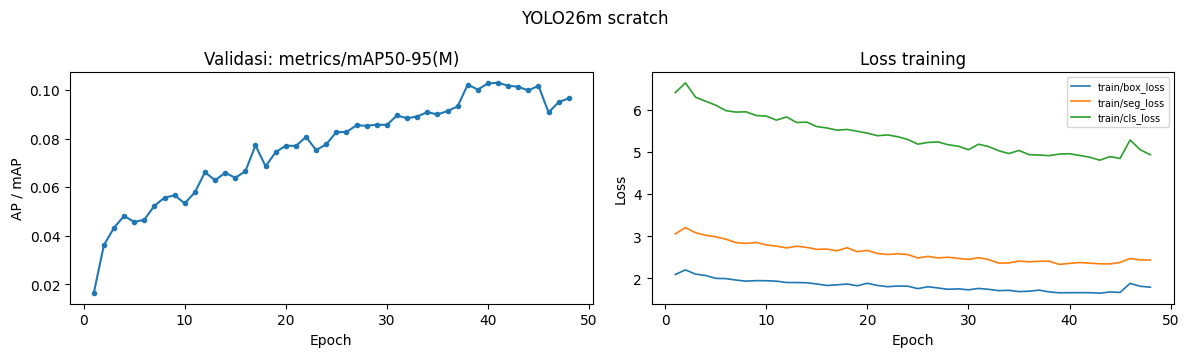

In [9]:
for _name in ("YOLO26m pretrained", "YOLO26m scratch"):
    show_run(_name, RUNS[_name])

## Swin-L + Mask2Former — pretrained dan scratch

Keduanya dijalankan di Modal pada L40S. Run pretrained berhenti lebih awal pada epoch 75/150; run scratch dihentikan manual pada epoch 68/150. `results.csv` dan log Modal adalah sumber grafik/cuplikan log.

### Swin-L pretrained — 75 baris tercatat
Log: reports\training_evidence\swin_l_mask2former\pretrained\train.log (ada)


,epoch,val_AP,loss_mean
67,68,NaN,14.6608
68,69,0.3193,13.3577
69,70,NaN,14.2327
70,71,NaN,13.4742
71,72,0.3258,14.3997
72,73,NaN,13.5689
73,74,NaN,13.8116
74,75,0.3078,10.9107


Cuplikan akhir log:
[15:32:42 + 7184.1s]   val ep75 thr=0.4 mask=0.5 AP=0.3078 AP50=0.4231 AP24=0.3186 n_pred=1388
[15:32:42 + 7184.1s]   tidak membaik: AP=0.3078 (best 0.3265 ep51) patience 8/8
[15:32:42 + 7184.1s] EARLY STOP ep75: 8 cek val tanpa perbaikan >0.0005 sejak ep51 (best 0.3265)
[15:32:43 + 7185.2s] EPOCH 75/150 77.9s 0.354s/it loss=10.9107 gn=552.08 vram=12.2GB val=AP=0.3078 AP24=0.3186 cum=$4.117
[15:32:47 + 7189.2s] SELESAI early_stop total=7172.6s ~$4.1183 best_AP=0.3265 ep51


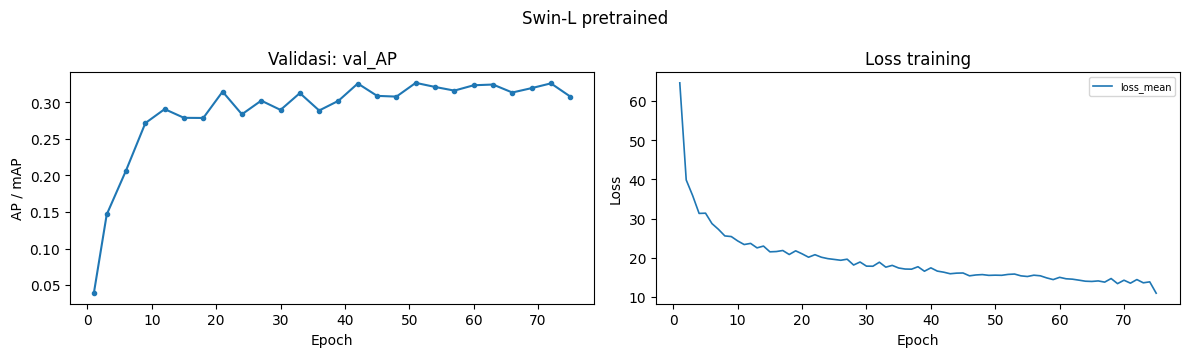

### Swin-L scratch — 68 baris tercatat
Log: reports\training_evidence\swin_l_mask2former\scratch\train.log (ada)


,epoch,val_AP,loss_mean
60,61,NaN,68.9068
61,62,NaN,68.4129
62,63,0.00014,69.7655
63,64,NaN,68.2334
64,65,NaN,67.9998
65,66,0.00004,68.8781
66,67,NaN,67.3801
67,68,NaN,67.7124


Cuplikan akhir log:
[01:39:39 + 7616.1s]   ep69 it15120/33000 loss=67.7139 gn=363.936 lr=1.22e-04
[01:39:46 + 7622.8s]   ep69 it15140/33000 loss=72.4391 gn=216.116 lr=1.22e-04
[01:39:52 + 7629.2s]   ep69 it15160/33000 loss=68.1779 gn=173.816 lr=1.22e-04
[01:39:58 + 7635.5s]   ep69 it15180/33000 loss=68.1518 gn=444.399 lr=1.22e-04
[01:40:16 + 7653.6s]   val ep69 thr=0.01 mask=0.3 AP=0.0000 AP50=0.0001 AP24=0.0000 n_pred=4726


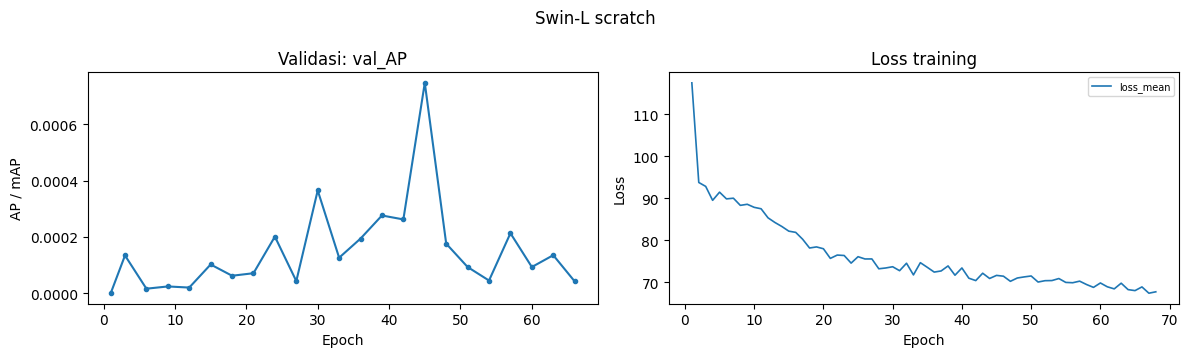

In [13]:
for _name in ("Swin-L pretrained", "Swin-L scratch"):
    show_run(_name, RUNS[_name])

## EVA-02-L + Cascade Mask R-CNN — pretrained dan scratch

Run pretrained dijalankan 40 epoch di Modal. Run scratch dihentikan manual di epoch 34 dari target 120; CSV mencatat pengukuran AP berkala, bukan setiap epoch. Jadi titik yang jarang pada grafik adalah sesuai frekuensi evaluasi sebenarnya.

### EVA-02-L pretrained — 40 baris tercatat
Log: reports\training_evidence\eva_cascade_mask_rcnn\pretrained\train.log (ada)


,epoch,val_AP,loss
32,33,NaN,0.6000
33,34,NaN,0.5814
34,35,0.31827,0.5719
35,36,NaN,0.5648
36,37,NaN,0.5666
37,38,NaN,0.5481
38,39,NaN,0.5613
39,40,0.32280,0.5547


Cuplikan akhir log:
[00:08:46]   ep40 it8700 loss 0.4557 gn 6.77 60s mem 15.3GB
[00:09:10]   ep40 it8750 loss 0.5085 gn 4.07 85s mem 15.3GB
[00:09:35]   ep40 it8800 loss 0.8627 gn 8.53 110s mem 15.3GB
[00:10:10] EPOCH 40/40 loss 0.5547 AP 0.322801 (best 0.322801 @ep40) 110s $3.0404
[00:10:15] SELESAI {"tag": "f0_rpnfix", "fold": 0, "epochs_done": 40, "epochs_target": 40, "best_AP": 0.322801, "best_epoch": 40, "peak_gb": 15.29, "total_sec": 5317.8, "s_per_epoch": 132.9, "usd_total": 3.0533, "early_stopped": false, "params_M": 365.6, "num_classes": 35, "imgsz": 640}


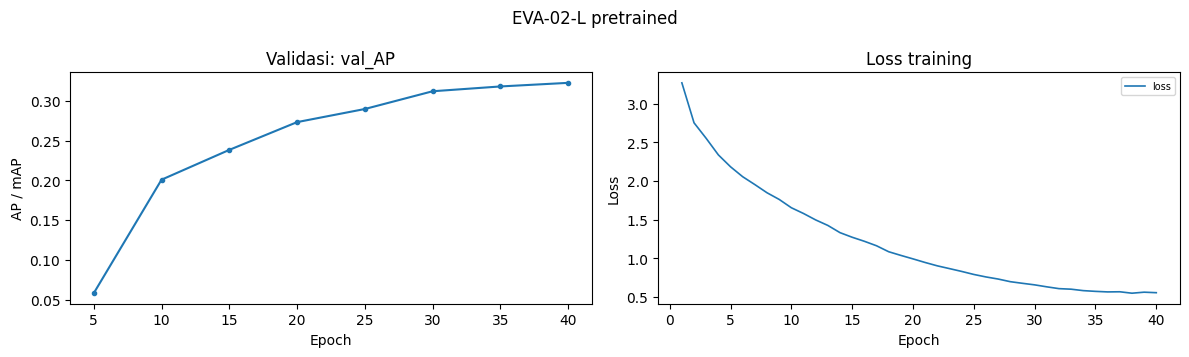

### EVA-02-L scratch — 34 baris tercatat
Log: reports\training_evidence\eva_cascade_mask_rcnn\scratch\train.log (ada)


,epoch,val_AP,loss
26,27,NaN,2.2171
27,28,NaN,2.1972
28,29,NaN,2.1586
29,30,0.01215,2.1041
30,31,NaN,2.0901
31,32,NaN,2.0552
32,33,NaN,2.0081
33,34,NaN,1.9658


Cuplikan akhir log:
[03:37:11]   ep35 it7500 loss 1.8900 gn 3.75 11s mem 15.0GB
[03:37:36]   ep35 it7550 loss 1.8913 gn 3.24 36s mem 15.0GB
[03:38:01]   ep35 it7600 loss 1.5126 gn 4.69 61s mem 15.0GB
[03:38:27]   ep35 it7650 loss 1.9530 gn 2.88 87s mem 15.0GB
[03:38:52]   ep35 it7700 loss 2.6583 gn 4.43 112s mem 15.0GB


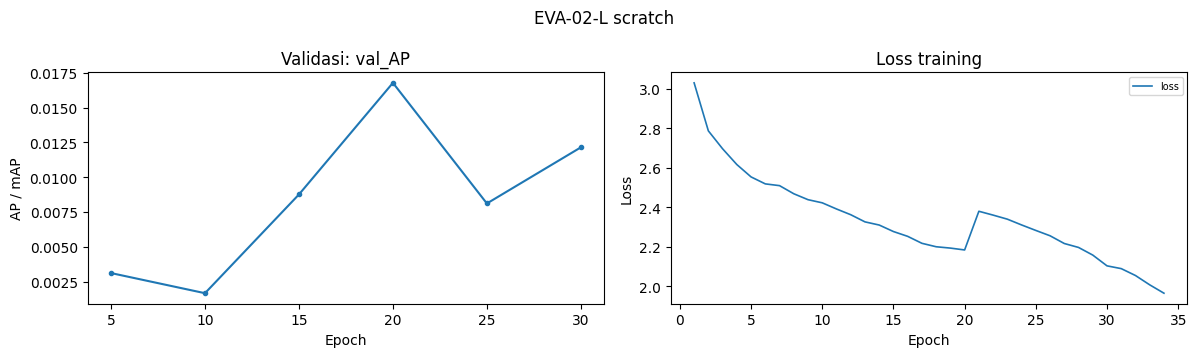

In [14]:
for _name in ("EVA-02-L pretrained", "EVA-02-L scratch"):
    show_run(_name, RUNS[_name])

## ECSeg-L — pretrained dan scratch

Kedua run lokal memakai EdgeCrafter dan 35 kelas. Pretrained warm-start dari bobot COCO; scratch memakai inisialisasi acak. Log ECSeg berbentuk JSON per epoch, sehingga helper mengekstrak `train_loss`, `test_coco_eval_mask[0]` (AP), dan `[1]` (AP50).

### ECSeg-L pretrained — 35 baris tercatat
Log: reports\training_evidence\ecseg_l\pretrained\log.txt (ada)


,epoch,val_AP,train_loss
27,28,0.43508,45.34039
28,29,0.43799,43.74374
29,30,0.43708,43.99649
30,31,0.44060,44.14308
31,32,0.44063,42.69599
32,33,0.44118,43.43995
33,34,0.44194,40.02798
34,35,0.44500,38.27536


Cuplikan log (metrik inti tiap epoch terakhir):
{'epoch': 33, 'train_loss': 43.44, 'val_AP': 0.441184, 'val_AP50': 0.612383}
{'epoch': 34, 'train_loss': 40.028, 'val_AP': 0.441945, 'val_AP50': 0.613041}
{'epoch': 35, 'train_loss': 38.2754, 'val_AP': 0.444998, 'val_AP50': 0.616896}


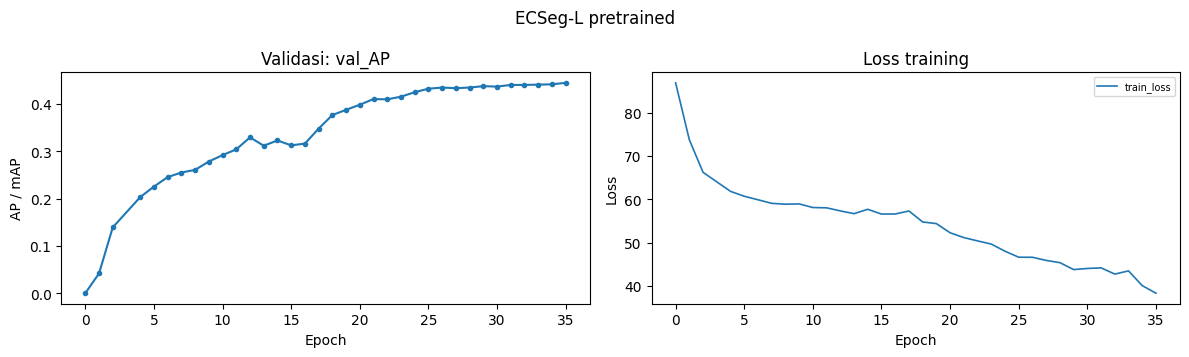

### ECSeg-L scratch — 30 baris tercatat
Log: reports\training_evidence\ecseg_l\scratch\log.txt (ada)


,epoch,val_AP,train_loss
22,22,0.00442,81.72847
23,23,0.00319,82.28187
24,24,0.00445,81.33895
25,25,0.00311,80.50975
26,26,0.00350,80.55781
27,27,0.00459,80.82717
28,28,0.00474,78.93265
29,29,0.00464,80.01347


Cuplikan log (metrik inti tiap epoch terakhir):
{'epoch': 27, 'train_loss': 80.8272, 'val_AP': 0.004588, 'val_AP50': 0.010503}
{'epoch': 28, 'train_loss': 78.9327, 'val_AP': 0.004737, 'val_AP50': 0.012145}
{'epoch': 29, 'train_loss': 80.0135, 'val_AP': 0.00464, 'val_AP50': 0.009684}


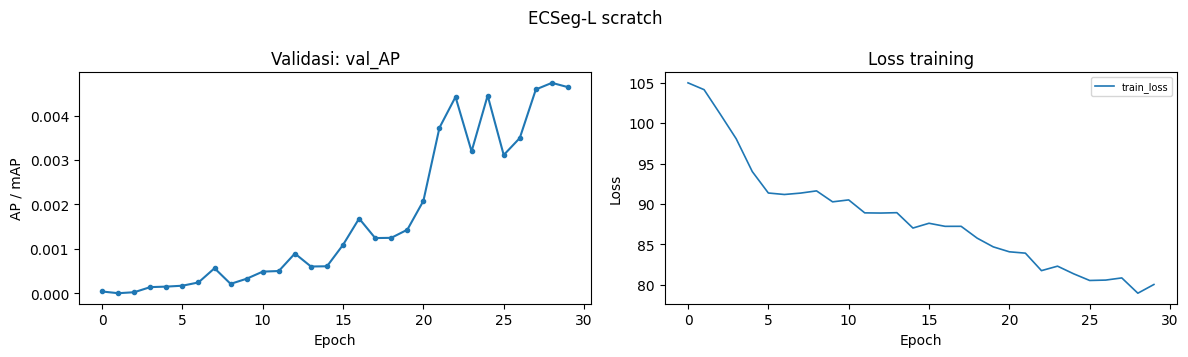

In [15]:
for _name in ("ECSeg-L pretrained", "ECSeg-L scratch"):
    show_run(_name, RUNS[_name])

## Ringkasan hasil terdokumentasi

Nilai berikut disalin dari `reports/MODEL_DIRECTORY.md` dan bukan dihasilkan oleh sel training. Run scratch Swin-L dan EVA tidak selesai sesuai target; label statusnya perlu dipertahankan saat membandingkan kurva.

In [16]:
summary = pd.DataFrame([
    ("YOLO26m", "pretrained", 0.3347, "mask mAP50-95; selesai, 24 epoch", "lokal"),
    ("YOLO26m", "scratch", 0.1016, "mask mAP50-95; selesai, 48 epoch pada run c3", "lokal"),
    ("Swin-L", "pretrained", 0.3265, "val mask AP; early-stop ep75/150", "Modal L40S"),
    ("Swin-L", "scratch", 0.000747, "best val mask AP; dihentikan manual ep68/150", "Modal L40S"),
    ("EVA-02-L", "pretrained", 0.322801, "val mask AP; complete 40/40", "Modal L40S"),
    ("EVA-02-L", "scratch", 0.016784, "best val mask AP; dihentikan manual ep34/120", "Modal L40S"),
    ("ECSeg-L", "pretrained", 0.4450, "segm AP; complete", "lokal"),
    ("ECSeg-L", "scratch", 0.004737, "best segm AP; complete 30/30", "lokal"),
], columns=["Model", "Arm", "AP", "Status / metrik", "Lokasi training"])
display(summary)

,Model,Arm,AP,Status / metrik,Lokasi training
0,YOLO26m,pretrained,0.334700,"mask mAP50-95; selesai, 24 epoch",lokal
1,YOLO26m,scratch,0.101600,"mask mAP50-95; selesai, 48 epoch pada run c3",lokal
2,Swin-L,pretrained,0.326500,val mask AP; early-stop ep75/150,Modal L40S
3,Swin-L,scratch,0.000747,best val mask AP; dihentikan manual ep68/150,Modal L40S
4,EVA-02-L,pretrained,0.322801,val mask AP; complete 40/40,Modal L40S
5,EVA-02-L,scratch,0.016784,best val mask AP; dihentikan manual ep34/120,Modal L40S
6,ECSeg-L,pretrained,0.445000,segm AP; complete,lokal
7,ECSeg-L,scratch,0.004737,best segm AP; complete 30/30,lokal
